# Rail Detection Deep Learning Project

In [3]:
# importing packages
import csv
import pandas as pd 
import os 
import shutil
import tensorflow as tf 
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report



## Reading the dataset 
Using pandas and shutil to move all the images in the dataset to the correct folder either "defective" or "non_defective" by first reading the csv file which came with the dataset and then finding those images and moving them.

In [4]:
df = pd.read_csv('train _combined.csv')
df.head()

# Sökvägen till varje directory
raw_directory = 'raw_data'
defective_directory = 'data/defective'
non_defective_directory = 'data/non_defective'

# Går igenom csv filen rad för rad 
for index, row in df.iterrows(): 
    file_name = row['images']
    label = row['labels']
    
    # Var bilderna ligger
    source = os.path.join(raw_directory, file_name)
    
    if label == 'Defective':
        destination = os.path.join(defective_directory, file_name)
    else: 
        destination = os.path.join(non_defective_directory, file_name)
    
    # Kolla om bilden redan finns i destination mappen 
    if not os.path.exists(destination):    
        # kopiera bilden till den rätta mappen 
        shutil.copy(source, destination)
    else: 
        # Om den redan finns -> Gör ingenting
        pass
    
    
print("Done with moving all the pictures")

Done with moving all the pictures


## Konstanter

In [5]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 1337

## Preprocessing 
Vi kommer inte få flera bilder direkt nu, eftersom hela processen körs "live" dvs att vi kommer lägga in hela data_augmentation som första lagret i modellen. PÅ det sättet kommer effekterna att appliceras live medan bilderna laddas upp till nätverket.

In [6]:
# Data Augmentation 
data_augmentation = keras.Sequential(
    [
         
        layers.RandomFlip("horizontal"), 
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1), 
        layers.RandomBrightness(0.1),
        layers.Rescaling(1./255)
    ], 
    name = "data_augmentation",
)

train_ds = tf.keras.utils.image_dataset_from_directory(
    "data", # Huvud foldern
    validation_split=0.2, 
    subset= "training",
    seed = SEED, 
    image_size = IMAGE_SIZE,
    batch_size = BATCH_SIZE,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "data",
    validation_split = 0.2,
    subset = "validation",
    seed = SEED, 
    image_size = IMAGE_SIZE,
    batch_size = BATCH_SIZE,
)

class_names = train_ds.class_names
print(class_names)


Found 1776 files belonging to 2 classes.
Using 1421 files for training.
Found 1776 files belonging to 2 classes.
Using 355 files for validation.
['defective', 'non_defective']


# Följande koden används för att visualisera bilderna efter data Augmentation för att se till att allting ser bra ut oc inga bilder förstörs

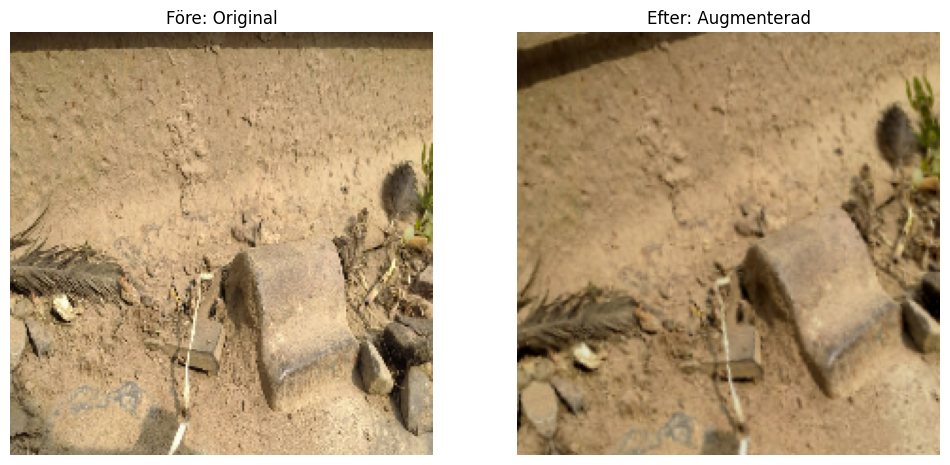

In [7]:


# Plocka ut EN batch (32 bilder) från träningsdatan
for images, lbls in train_ds.take(1):
    frst_img = images[0]
    
    # För att få plats med två bilder bredvid varandra och jämföra dessa med varandra 
    plt.figure(figsize=(12, 6))
    
    # Plats för orginal bilden till vänster
    plt.subplot(1, 2, 1) 
    
    # Omvandlar 0-255 till 0-1 floats för plt 
    original_to_plot = frst_img.numpy() / 255.0
    original_to_plot = np.clip(original_to_plot, 0, 1)
    
    plt.imshow(original_to_plot)
    plt.title("Före: Original")
    plt.axis("off")
    
    
    # Place for the Augmentated pictures on the right side
    plt.subplot(1, 2, 2) # 1 rad, 2 kolumner, bild 2
    
    # Skickar bilden genom första layer
    augmented_image = data_augmentation(tf.expand_dims(frst_img, 0), training=True)
    
    # Normalisera bilden 
    aug_to_plot = augmented_image[0].numpy()
    aug_to_plot = np.clip(aug_to_plot, 0, 1)
    
    plt.imshow(aug_to_plot)
    plt.title("Efter: Augmenterad")
    plt.axis("off")
    
    # Sparar bilden till rapporten 
    plt.savefig('before_and_after_augmentation.png', bbox_inches='tight')
    plt.show()

In [8]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size = AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size = AUTOTUNE)

# Now we create the model 
build the simple baseline CNN from scratch.

In [9]:
# we use the sequential type because the model is a simple layer-by-layer pipeline.
model = keras.Sequential([
    
    #This is the layer that applies augmentation during training.
    data_augmentation,

    #Then comes the first convolutional layer:
        #Conv2D learns small visual patterns, such as edges, lines, cracks and texture.
    layers.Conv2D(32, 3, activation="relu"),

    #MaxPooling reduces the images size.
    layers.MaxPooling2D(),

    #Second convolution layer. 
        #This learns more complex patterns based on the first layer's simple patterns.
    layers.Conv2D(64, 3, activation="relu"),

    #MaxPooling reduces the images size again.
    layers.MaxPooling2D(),

    # This learns even higher-level patterns, such as damaged rail shapes or larger textures.
    layers.Conv2D(128, 3, activation="relu"),

    # Reduce size again before sending features to the classifier part.
    layers.MaxPooling2D(),

    # Instead of flattening every pixel location into a huge vector,
    # this averages each feature map into one number.
    layers.GlobalAveragePooling2D(),


    # This combines the learned image features to make a classification decision.
    layers.Dense(64, activation="relu"),


    # Now using "Dropout" the model drops out randomly 30% of neurons during training to help prevent the model from memorizing the training images 

    layers.Dropout(0.3),

    # We use 1 neuron because this is binary classification.
    # Sigmoid outputs a probability between 0 and 1.
    # Example: 0.90 means the model strongly predicts class 1.
    layers.Dense(1, activation="sigmoid")
])

In [10]:
# This helps you check the number of layers, output shapes, and trainable parameters.
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (1, 222, 222, 32)      │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (1, 111, 111, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (1, 109, 109, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (1, 54, 54, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (1, 52, 52, 128)       │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (1, 26, 26, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (1, 128)               │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 64)                │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (1, 64)                │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 1)                 │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

# Next step is to compile the model 

In [11]:
model.compile(

    #First we choose the optimizer Adam 
    optimizer="adam",

    #We choose the loss function 
    loss="binary_crossentropy",

    metrics=[

        "accuracy",

        keras.metrics.Precision(name="precision"),

        keras.metrics.Recall(name="recall")
    ]
)

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (1, 222, 222, 32)      │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (1, 111, 111, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (1, 109, 109, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (1, 54, 54, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (1, 52, 52, 128)       │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (1, 26, 26, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (1, 128)               │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 64)                │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (1, 64)                │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 1)                 │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

# Training the model now 


In [13]:
EPOCHS = 25 


history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 11s 219ms/step - accuracy: 0.4926 - loss: 0.6948 - precision: 0.4974 - recall: 0.5286 - val_accuracy: 0.4817 - val_loss: 0.6953 - val_precision: 0.4817 - val_recall: 1.0000
Epoch 2/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 170ms/step - accuracy: 0.4856 - loss: 0.6945 - precision: 0.4914 - recall: 0.5565 - val_accuracy: 0.5127 - val_loss: 0.6922 - val_precision: 0.4970 - val_recall: 0.9766
Epoch 3/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 177ms/step - accuracy: 0.5144 - loss: 0.6933 - precision: 0.5164 - recall: 0.5927 - val_accuracy: 0.5521 - val_loss: 0.6869 - val_precision: 0.5190 - val_recall: 0.9591
Epoch 4/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 172ms/step - accuracy: 0.5109 - loss: 0.6914 - precision: 0.5128 - recall: 0.6165 - val_accuracy: 0.4817 - val_loss: 0.6916 - val_precision: 0.4817 - val_recall: 1.0000
Epoch 5/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 174ms/step - accuracy: 0.5376 - loss: 0.6917 - precision: 0.5371 - recall: 0.6053 - val_accuracy: 0.6366 - val_loss: 0

# Record accuracy, loss, precision, recall, and F1-score


In [14]:

# Convert the training history into a table.

history_df = pd.DataFrame(history.history)

# F1-score combines precision and recall into one value.
# Formula: F1 = 2 * (precision * recall) / (precision + recall)
# We add a very small number (1e-7) to avoid division by zero.
history_df["f1_score"] = 2 * (
    history_df["precision"] * history_df["recall"]
) / (history_df["precision"] + history_df["recall"] + 1e-7)

# Validation F1-score uses validation precision and validation recall.
# This is important because validation results better show performance on unseen data.
history_df["val_f1_score"] = 2 * (
    history_df["val_precision"] * history_df["val_recall"]
) / (history_df["val_precision"] + history_df["val_recall"] + 1e-7)

# Add an epoch number column so the table is easier to read.
history_df["epoch"] = range(1, len(history_df) + 1)

# Choose the columns we want to record for the project report.
metrics_table = history_df[[
    "epoch",
    "accuracy",
    "loss",
    "precision",
    "recall",
    "f1_score",
    "val_accuracy",
    "val_loss",
    "val_precision",
    "val_recall",
    "val_f1_score"
]]

# Save the metrics table as a CSV file.
# This gives you a permanent record of the baseline CNN results.
metrics_table.to_csv("baseline_cnn_metrics.csv", index=False)

# Show the table inside the notebook.
metrics_table

,epoch,accuracy,loss,precision,recall,f1_score,val_accuracy,val_loss,val_precision,val_recall,val_f1_score
0,1,0.492611,0.694838,0.497375,0.528591,0.512508,0.481690,0.695281,0.481690,1.000000,0.650190
1,2,0.485574,0.694494,0.491379,0.556485,0.521910,0.512676,0.692222,0.497024,0.976608,0.658777
2,3,0.514426,0.693262,0.516403,0.592748,0.551948,0.552113,0.686920,0.518987,0.959064,0.673511
3,4,0.510908,0.691405,0.512761,0.616457,0.559848,0.481690,0.691624,0.481690,1.000000,0.650190
4,5,0.537650,0.691704,0.537129,0.605300,0.569180,0.636620,0.674525,0.605000,0.707602,0.652291
5,6,0.563688,0.675671,0.563069,0.603905,0.582772,0.588732,0.669131,0.543554,0.912281,0.681223
6,7,0.570021,0.667951,0.570479,0.598326,0.584071,0.600000,0.657061,0.649485,0.368421,0.470149
7,8,0.583392,0.665407,0.572590,0.687587,0.624842,0.512676,0.692730,0.497059,0.988304,0.661448
8,9,0.556650,0.675472,0.546326,0.715481,0.619565,0.656338,0.634611,0.652174,0.614035,0.632530
9,10,0.620690,0.648512,0.606205,0.708508,0.653376,0.577465,0.650036,0.534884,0.941520,0.682203


# Save plots for training/validation accuracy and loss

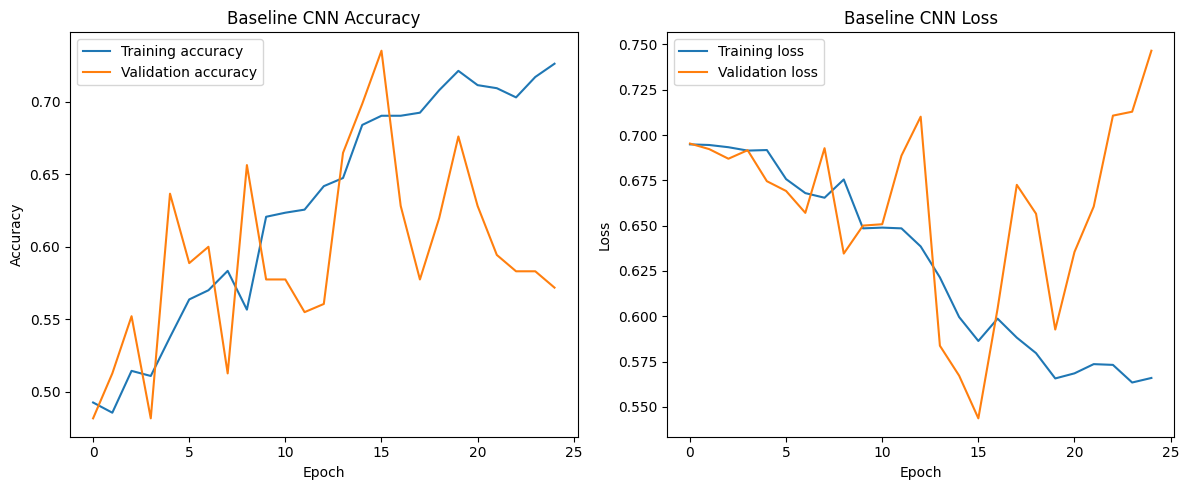

In [15]:


# Create one figure with two plots side by side.
plt.figure(figsize=(12, 5))

# Plot 1: training accuracy vs validation accuracy.
# If training accuracy is much higher than validation accuracy, the model may be overfitting.
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN Accuracy")
plt.legend()

# Plot 2: training loss vs validation loss.
# Loss tells us how wrong the model is; lower loss is better.
# If validation loss rises while training loss falls, that is another sign of overfitting.
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN Loss")
plt.legend()

# tight_layout makes sure labels and titles do not overlap.
plt.tight_layout()

# Save the plot for the report.
plt.savefig("baseline_cnn_accuracy_loss.png", dpi=300, bbox_inches="tight")

# Display the plot in the notebook.
plt.show()

# Print the final recorded results

In [16]:
# Get the last row from the metrics table.
# The last row represents the final epoch of training.
final_results = metrics_table.iloc[-1]

# Print the final training and validation metrics in a readable format.
print("Final baseline CNN results")
print("Training accuracy:", final_results["accuracy"])
print("Training loss:", final_results["loss"])
print("Training precision:", final_results["precision"])
print("Training recall:", final_results["recall"])
print("Training F1-score:", final_results["f1_score"])
print("Validation accuracy:", final_results["val_accuracy"])
print("Validation loss:", final_results["val_loss"])
print("Validation precision:", final_results["val_precision"])
print("Validation recall:", final_results["val_recall"])
print("Validation F1-score:", final_results["val_f1_score"])

Final baseline CNN results
Training accuracy: 0.726249098777771
Training loss: 0.5660010576248169
Training precision: 0.7204301357269287
Training recall: 0.7475592494010925
Training F1-score: 0.7337439633812944
Validation accuracy: 0.5718309879302979
Validation loss: 0.7464914917945862
Validation precision: 0.5326460599899292
Validation recall: 0.9064327478408813
Validation F1-score: 0.6709956336043431


# Evaluation of the models performance per class 
we collect the correct labels from the validation dataset and the predited labels from the model history to create a confusion matrix

In [17]:
# y_true will store the true labels from the validation data 
y_true = []

# y_pred will store the labels predicted by the trainde model 
y_pred = []

for images, labels in val_ds:

    probabilities = model.predict(images)

    #convert predicted probabilites into 1D array with class labels 1 and 0 
    predicted_labels = (probabilities >= 0.5).astype("int32").flatten()

    #adding the real labels to y_true.
    y_true.extend(labels.numpy())

    #adding the predicted labels to y_pred.
    y_pred.extend(predicted_labels)


#Convert lists into numpy arrays so that sklearn can work with them easier 
y_true = np.array(y_true)
y_pred = np.array(y_pred)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


In [18]:
# This confirms that we have one prediction for each real label.
print("Class names:", class_names)
print("Number of real labels:", len(y_true))
print("Number of predicted labels:", len(y_pred))

Class names: ['defective', 'non_defective']
Number of real labels: 355
Number of predicted labels: 355


# Confusion matrix 

In [19]:
#using the sklearn built in confusion matrix 
cm = confusion_matrix(y_true, y_pred)

# Create the classification report.
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

In [20]:
print("Class names:", class_names)

# Print the confusion matrix.
print(cm)

# Print the classification report.
print(report)

Class names: ['defective', 'non_defective']
[[ 48 136]
 [ 16 155]]
               precision    recall  f1-score   support

    defective       0.75      0.26      0.39       184
non_defective       0.53      0.91      0.67       171

     accuracy                           0.57       355
    macro avg       0.64      0.58      0.53       355
 weighted avg       0.65      0.57      0.52       355



The baseline CNN trained from scratch showed limited ability to detect defective rails.
Although it classified non-defective images well, it missed many defective examples.
This suggests that the model did not learn sufficiently strong defect-related features from the available dataset.
Therefore, transfer learning with a pretrained CNN such as ResNet50 is expected to improve performance.


# We now save the evaluation results 

In [21]:
with open("baseline_cnn_classification_report.txt", "w") as file:

    file.write("Class names: " + str(class_names) + "\n\n")

    file.write("Confusion matrix:\n")
    file.write(str(cm))
    file.write("\n\n")


    file.write("Classification report:\n")
    file.write(report)


print("Saved evaluation report to baseline_cnn_classification_report.txt")


Saved evaluation report to baseline_cnn_classification_report.txt


# Transfer Learing With ResNet50 
Using a pretrained ResNet50 backbone with ImageNet weights, the backbone will be frozen. 

## Transfer Learning With ResNet50 Data Augmentation layer

In [22]:
from tensorflow.keras.applications.resnet50 import preprocess_input

resnet50_augmentation = keras.Sequential ([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1)
], name="resnet50_augmentation")

In [23]:
# Pretrained resNet50 without org classification head
resnet50_backbone = keras.applications.ResNet50(
    weights = "imagenet",
    include_top = False,
    input_shape = (224,224, 3)
)

# Freeze the backbone of the pretrained model
resnet50_backbone.trainable = False

# Build the Transfer Learning model
resnet50_model =keras.Sequential([
    resnet50_augmentation, layers.Lambda(preprocess_input),resnet50_backbone, layers.GlobalAveragePooling2D(), layers.Dropout(0.2), layers.Dense(1, activation="sigmoid")
])

# Checking the structure of the model 
resnet50_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50_augmentation           │ ?                      │   0 (unbuilt) │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

## Compile ResNet 


In [24]:
resnet50_model.compile(
    optimizer = "adam",
    loss= "binary_crossentropy",
    metrics = ["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")]
)

## Train the model 

In [25]:
EPOCHS_RESNET = 35

history_resnet = resnet50_model.fit(
    train_ds, 
    validation_data= val_ds,
    epochs = EPOCHS_RESNET
)

Epoch 1/35

45/45 ━━━━━━━━━━━━━━━━━━━━ 28s 568ms/step - accuracy: 0.6256 - loss: 0.6802 - precision: 0.6265 - recall: 0.6388 - val_accuracy: 0.6761 - val_loss: 0.6715 - val_precision: 0.6061 - val_recall: 0.9357
Epoch 2/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 24s 524ms/step - accuracy: 0.7277 - loss: 0.5433 - precision: 0.7285 - recall: 0.7336 - val_accuracy: 0.7183 - val_loss: 0.5778 - val_precision: 0.6537 - val_recall: 0.8830
Epoch 3/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 23s 523ms/step - accuracy: 0.7523 - loss: 0.5047 - precision: 0.7531 - recall: 0.7573 - val_accuracy: 0.7268 - val_loss: 0.5809 - val_precision: 0.6555 - val_recall: 0.9123
Epoch 4/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 23s 524ms/step - accuracy: 0.7614 - loss: 0.4946 - precision: 0.7625 - recall: 0.7657 - val_accuracy: 0.7239 - val_loss: 0.5472 - val_precision: 0.6527 - val_recall: 0.9123
Epoch 5/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 23s 524ms/step - accuracy: 0.7882 - loss: 0.4605 - precision: 0.7897 - recall: 0.7908 - val_accuracy: 0.7239 - val_lo

# Record Accuracy, loss, precision, recall and F1 Score for ResNet50 

In [26]:
# Making a table of the training history
history_df = pd.DataFrame(history_resnet.history)

# F1 Score combines precision and recall into one value
history_df["f1_score"] = 2 * (history_df["precision"] * history_df["recall"]) / (history_df["precision"] + history_df["recall"] + 1e-7)

# Validation F1 score uses validation precision and validation recall
history_df["val_f1_score"] = 2 * (history_df["val_precision"] * history_df["val_recall"]) / (history_df["val_precision"] + history_df["val_recall"] + 1e-7)

# Add an epoch number column so the table is easier to read 
history_df["epoch"] = range(1, len(history_df) +1)

# Choose the columns we want to record for the project report
metrics_table = history_df[[
    "epoch",
    "accuracy",
    "loss",
    "precision",
    "recall",
    "f1_score",
    "val_accuracy",
    "val_loss",
    "val_precision",
    "val_recall",
    "val_f1_score"
]]

# Save the metrics table as a CSV file
metrics_table.to_csv("resnet50_metrics.cvs", index=False)

# Show the table below 
metrics_table

,epoch,accuracy,loss,precision,recall,f1_score,val_accuracy,val_loss,val_precision,val_recall,val_f1_score
0,1,0.625616,0.680247,0.626539,0.638773,0.632597,0.676056,0.671550,0.606061,0.935673,0.735632
1,2,0.727657,0.543284,0.728532,0.733612,0.731063,0.718310,0.577755,0.653680,0.883041,0.751244
2,3,0.752287,0.504722,0.753121,0.757322,0.755216,0.726761,0.580920,0.655462,0.912281,0.762836
3,4,0.761436,0.494612,0.762500,0.765690,0.764092,0.723944,0.547152,0.652720,0.912281,0.760976
4,5,0.788177,0.460542,0.789694,0.790795,0.790244,0.723944,0.561974,0.648980,0.929825,0.764423
5,6,0.796622,0.448372,0.793151,0.807531,0.800276,0.746479,0.557648,0.668050,0.941520,0.781553
6,7,0.786066,0.435586,0.789621,0.785216,0.787413,0.735211,0.567123,0.657143,0.941520,0.774038
7,8,0.807178,0.422138,0.802183,0.820084,0.811034,0.743662,0.539868,0.668067,0.929825,0.777506
8,9,0.800141,0.425049,0.792963,0.817294,0.804945,0.754930,0.498043,0.685841,0.906433,0.780856
9,10,0.813512,0.405226,0.810440,0.822873,0.816609,0.757746,0.519077,0.683983,0.923977,0.786070


## Show and save the graphs of ResNet50 Results

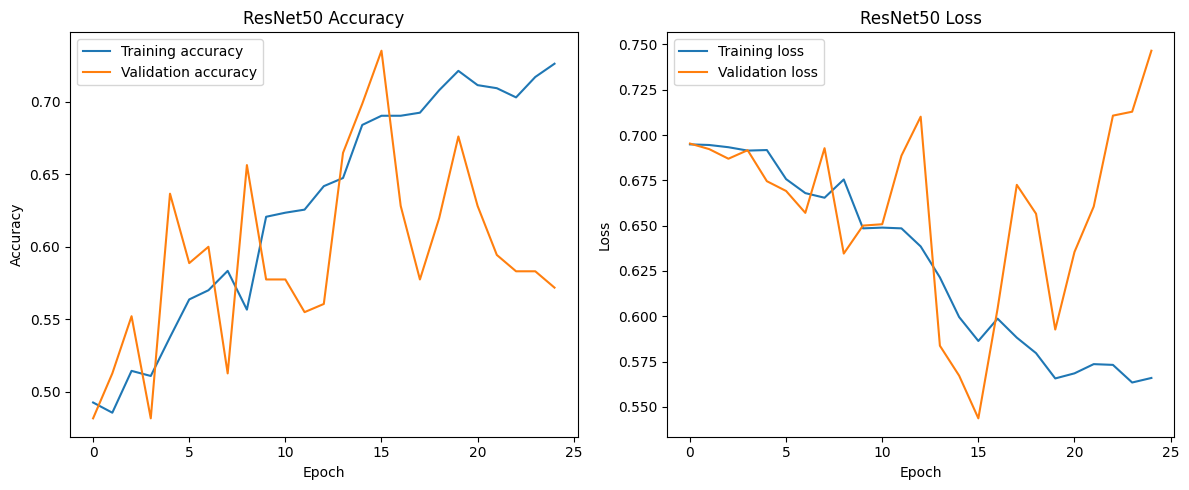

In [27]:
# One figure with 2 plots side by side
plt.figure(figsize=(12, 5))

# Plot 1: training accuracy vs validation accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Accuracy")
plt.legend()

# Plot 2: traing loss vs validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Loss")
plt.legend()

# Make sure labels and titles don't overlap
plt.tight_layout()

# Save the plot for the report
plt.savefig("resnet50_accuracy_loss.png", dpi=300, bbox_inches="tight")

# Show the graph below

## Print the final record results 

In [28]:
# Get the last row from the metrics table.
# The last row represents the final epoch of training.
final_results = metrics_table.iloc[-1]

# Print the final training and validation metrics in a readable format.
print("Final ResNet50 results")
print("Training accuracy:", final_results["accuracy"])
print("Training loss:", final_results["loss"])
print("Training precision:", final_results["precision"])
print("Training recall:", final_results["recall"])
print("Training F1-score:", final_results["f1_score"])
print("Validation accuracy:", final_results["val_accuracy"])
print("Validation loss:", final_results["val_loss"])
print("Validation precision:", final_results["val_precision"])
print("Validation recall:", final_results["val_recall"])
print("Validation F1-score:", final_results["val_f1_score"])

Final ResNet50 results
Training accuracy: 0.8360309600830078
Training loss: 0.3442371189594269
Training precision: 0.8370473384857178
Training recall: 0.8382147550582886
Training F1-score: 0.8376305900113632
Validation accuracy: 0.8028169274330139
Validation loss: 0.4330421984195709
Validation precision: 0.734883725643158
Validation recall: 0.9239766001701355
Validation F1-score: 0.818652800168194


## Confusion Matrix and Classifcation Report

In [29]:
# y_true will store the true labels from the validation data 
y_true = []

# y_pred will store the labels predicted by the trainde model 
y_pred = []

for images, labels in val_ds:

    probabilities = resnet50_model.predict(images)

    #convert predicted probabilites into 1D array with class labels 1 and 0 
    predicted_labels = (probabilities >= 0.5).astype("int32").flatten()

    #adding the real labels to y_true.
    y_true.extend(labels.numpy())

    #adding the predicted labels to y_pred.
    y_pred.extend(predicted_labels)


#Convert lists into numpy arrays so that sklearn can work with them easier 
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# This confirms that we have one prediction for each real label.
print("Class names:", class_names)
print("Number of real labels:", len(y_true))
print("Number of predicted labels:", len(y_pred))

#using the sklearn built in confusion matrix 
cm = confusion_matrix(y_true, y_pred)

# Create the classification report.
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print("Class names:", class_names)

# Print the confusion matrix.
print(cm)

# Print the classification report.
print(report)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 457ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 447ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 463ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 440ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 440ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 441ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 447ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 786ms/step
Class names: ['defective', 'non_defective']
Number of real labels: 355
Number of predicted labels: 355
Class names: ['defective', 'non_defective']
[[127  57]
 [ 13 158]]
               precision    recall  f1-score   support

    defective       0.91      0.69      0.78       184
non_defective       0.73      0.92      0.82       171

     accuracy                           0.80       355
    macro avg       0.82      0.81      0.80       355
 weighted avg       0.82      0.80      0.80       355



## Save the Evaluation Results of ResNet50 in a file 


In [30]:
with open("resnet50_classification_report.txt", "w") as file:

    file.write("Class names: " + str(class_names) + "\n\n")

    file.write("Confusion matrix:\n")
    file.write(str(cm))
    file.write("\n\n")


    file.write("Classification report:\n")
    file.write(report)


print("Saved evaluation report to resnet50_classification_report.txt")

Saved evaluation report to resnet50_classification_report.txt
